# Выбор локации для скважины

Допустим, вы работаете в добывающей компании «ГлавРосГосНефть». Нужно решить, где бурить новую скважину.

Вам предоставлены пробы нефти в трёх регионах: в каждом 100 000 месторождений, где измерили качество нефти и объём её запасов. Постройте модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Проанализируйте возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

## Загрузка и подготовка данных

Для начала загрузим требуемые для выполнения проекта библиотеки

In [1]:
!pip install scikit-learn==1.1.3 -q

In [2]:
!pip install phik -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from phik import phik_matrix
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from statistics import stdev

from sklearn.metrics import mean_squared_error

from sklearn.linear_model import LinearRegression

Загрузим данные нашего проекта

In [4]:
data_0 = pd.read_csv('/datasets/geo_data_0.csv')
data_1 = pd.read_csv('/datasets/geo_data_1.csv')
data_2 = pd.read_csv('/datasets/geo_data_2.csv')

Ознакомимся с данными

In [5]:
display(data_0.head(5))
display(data_1.head(5))
display(data_2.head(5))

,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


In [6]:
data_0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [7]:
data_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [8]:
data_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [9]:
display(data_0.describe())
display(data_1.describe())
display(data_2.describe())

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.500419,0.250143,2.502647,92.500000
std,0.871832,0.504433,3.248248,44.288691
min,-1.408605,-0.848218,-12.088328,0.000000
25%,-0.072580,-0.200881,0.287748,56.497507
50%,0.502360,0.250252,2.515969,91.849972
75%,1.073581,0.700646,4.715088,128.564089
max,2.362331,1.343769,16.003790,185.364347


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.141296,-4.796579,2.494541,68.825000
std,8.965932,5.119872,1.703572,45.944423
min,-31.609576,-26.358598,-0.018144,0.000000
25%,-6.298551,-8.267985,1.000021,26.953261
50%,1.153055,-4.813172,2.011479,57.085625
75%,8.621015,-1.332816,3.999904,107.813044
max,29.421755,18.734063,5.019721,137.945408


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.002023,-0.002081,2.495128,95.000000
std,1.732045,1.730417,3.473445,44.749921
min,-8.760004,-7.084020,-11.970335,0.000000
25%,-1.162288,-1.174820,0.130359,59.450441
50%,0.009424,-0.009482,2.484236,94.925613
75%,1.158535,1.163678,4.858794,130.595027
max,7.238262,7.844801,16.739402,190.029838


Все данные соответстуют своим типам и считались корректно. На данном этапе можно сказать, что пропусков нет, также стоит отметить, что несмотря на то, что данные выглядят так будто они стандартизированы, на самом деле это не так, так как не все столбцы центрированы вокруг значения близкого к нулю и имеют стандартное отклонение большее 1. Давайте рассмотрим, как все обстоит с явными дубликатами, неявных нет, так как нет категориальных столбцов

In [10]:
print('Дубликаты в датафрейме по 1 региону',data_0.duplicated().sum())
print('Дубликаты в датафрейме по 2 региону',data_1.duplicated().sum())
print('Дубликаты в датафрейме по 3 региону',data_2.duplicated().sum())

Дубликаты в датафрейме по 1 региону 0
Дубликаты в датафрейме по 2 региону 0
Дубликаты в датафрейме по 3 региону 0


Столбец с индексами является категориальным, поэтому стоит убрать из него дубликаты

In [11]:
data_0 = data_0.drop_duplicates(subset='id',keep='first')
data_1 = data_1.drop_duplicates(subset='id',keep='first')
data_2 = data_2.drop_duplicates(subset='id',keep='first')

Проведем исследовательский анализ данных, идем по порядку, начнём с data_0, построим для него диаграммы размаха, а потом гистограммы распределений признаков

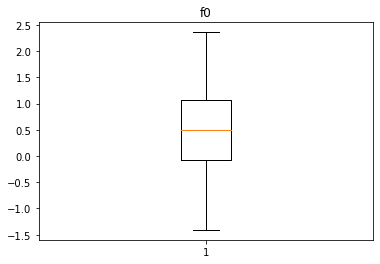

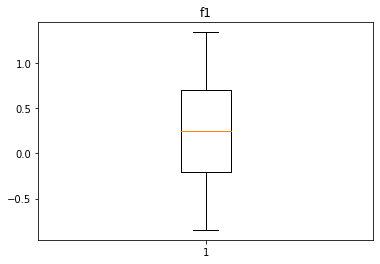

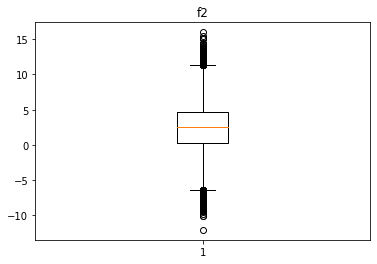

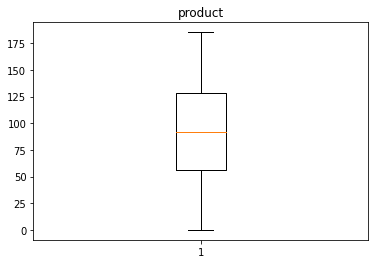

In [12]:
num_cols_0 = ['f0','f1','f2','product']
for column in num_cols_0:
    plt.title(column)
    plt.boxplot(data_0[column])
    plt.show()

Выбросов нет, можем перейти к гистограммам

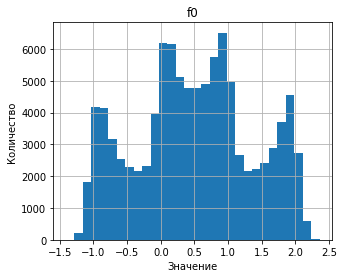

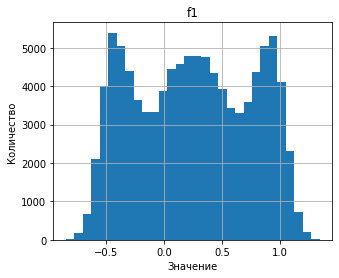

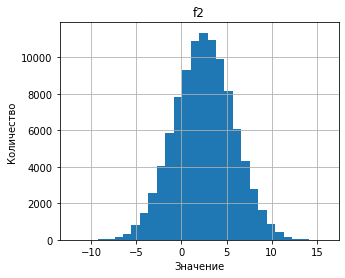

распределение относится к norm распределению


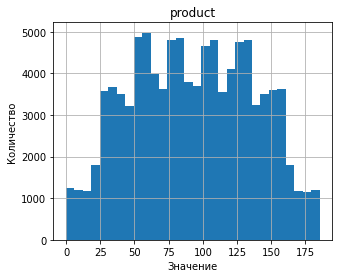

In [13]:
distr = ['norm', 'expon', 'uniform', 'gamma', 'beta']

for column in num_cols_0:
    plt.title(column)
    data_0[column].hist(bins=30,figsize=(5,4))
    plt.xlabel('Значение')
    plt.ylabel('Количество')
    plt.show()
    for d in distr:
        if stats.kstest(data_0[column], 'norm', args=(data_0[column].mean(),stdev(data_0[column])), alternative='two-sided').pvalue>0.05:
            print('распределение относится к',d,'распределению')
            if d in distr:
                break

Распределение признака f2 нормальное, остальные распределения имеют мультимодальность и симметричность

Перейдем ко второй таблице

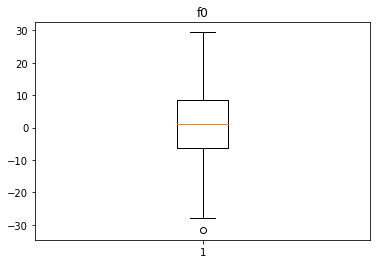

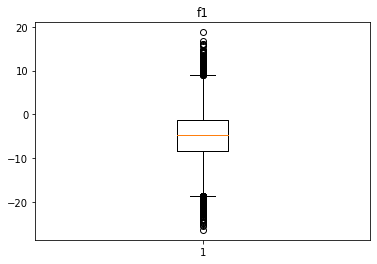

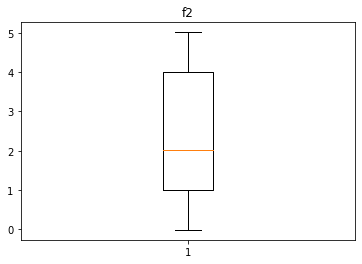

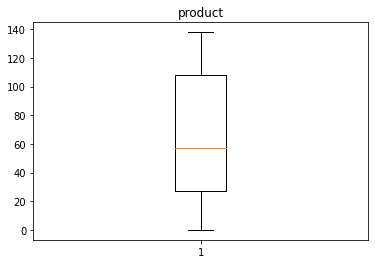

In [14]:
for column in num_cols_0:
    plt.title(column)
    plt.boxplot(data_1[column])
    plt.show()

Здесь тоже выбросов нет, че там по гистограммам

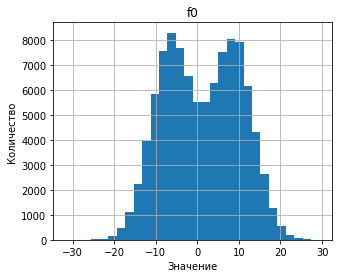

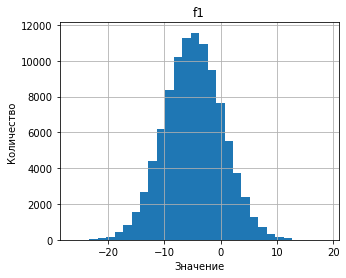

распределение относится к norm распределению


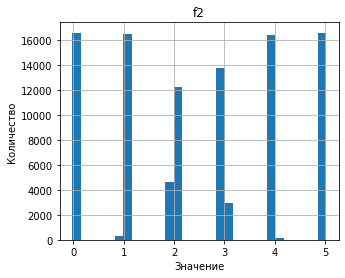

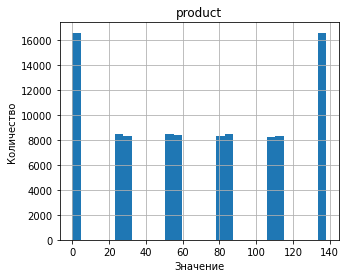

In [15]:
for column in num_cols_0:
    plt.title(column)
    data_1[column].hist(bins=30,figsize=(5,4))
    plt.xlabel('Значение')
    plt.ylabel('Количество')
    plt.show()
    for d in distr:
        if stats.kstest(data_1[column], 'norm', args=(data_1[column].mean(),stdev(data_1[column])), alternative='two-sided').pvalue>0.05:
            print('распределение относится к',d,'распределению')
            if d in distr:
                break

В данном датафрейме нормальное распределение имеет признак f1, остальные также имеют симметричность и мультимодальность

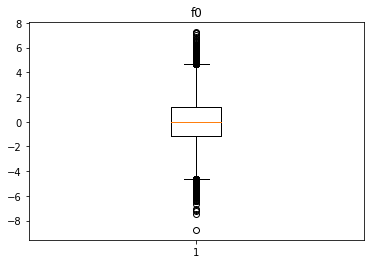

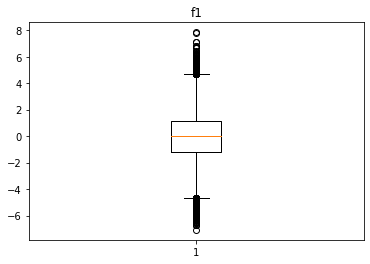

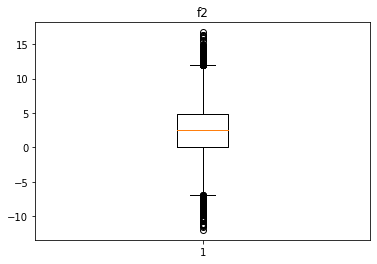

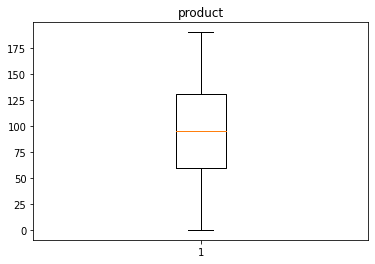

In [16]:
for column in num_cols_0:
    plt.title(column)
    plt.boxplot(data_2[column])
    plt.show()

Выбросов нет

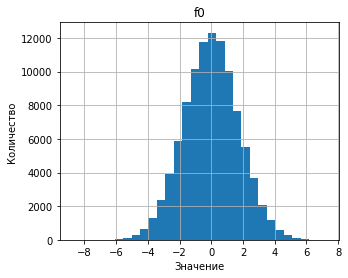

распределение относится к norm распределению


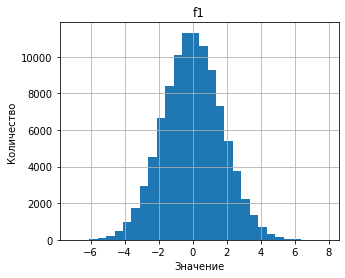

распределение относится к norm распределению


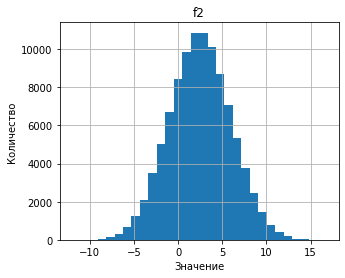

распределение относится к norm распределению


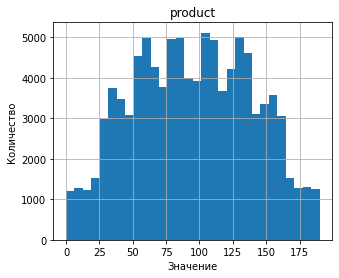

In [17]:
for column in num_cols_0:
    plt.title(column)
    data_2[column].hist(bins=30,figsize=(5,4))
    plt.xlabel('Значение')
    plt.ylabel('Количество')
    plt.show()
    for d in distr:
        if stats.kstest(data_2[column], 'norm', args=(data_2[column].mean(),stdev(data_2[column])), alternative='two-sided').pvalue>0.05:
            print('распределение относится к',d,'распределению')
            if d in distr:
                break

Распределение всех входных признаков нормальное, а таргетный признак опять таки симметричный и мультимодальный

Давайте проведем корреляционный анализ данных

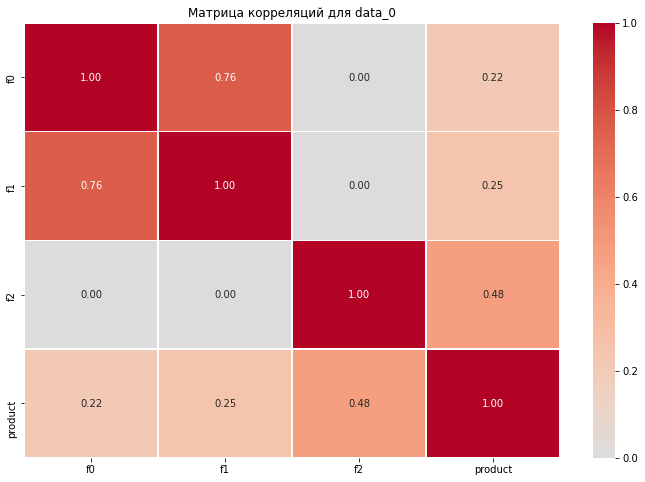

In [18]:
phik_overview = data_0.drop('id',axis=1).phik_matrix(interval_cols=num_cols_0)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций для data_0")
plt.show()

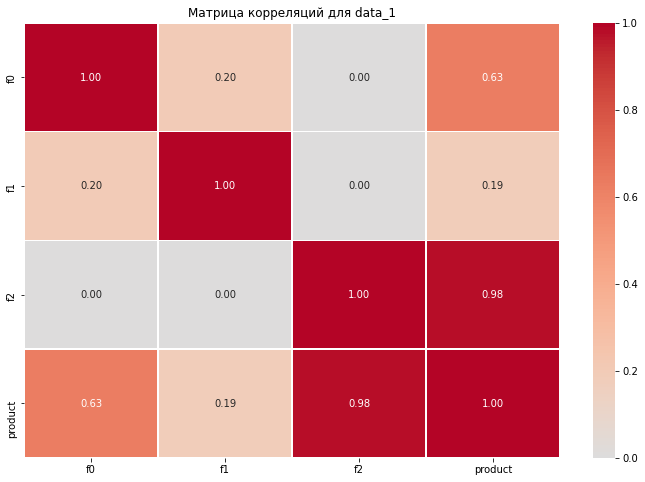

In [19]:
phik_overview = data_1.drop('id',axis=1).phik_matrix(interval_cols=num_cols_0)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций для data_1")
plt.show()

Здесь в третьем входном признаке есть утечка целевого признака

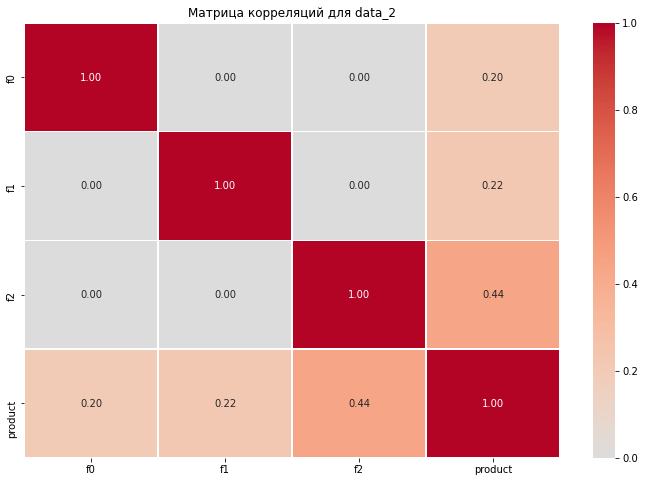

In [20]:
phik_overview = data_2.drop('id',axis=1).phik_matrix(interval_cols=num_cols_0)

plt.figure(figsize=(12, 8))
sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
plt.title("Матрица корреляций для data_2")
plt.show()

## Обучение и проверка модели

Будем идти по порядку, начнем с data_0, для начала разделим данные на тренировочную и валидационную выборки, подготовим данные к обучению и обучим саму модель

In [21]:
RANDOM_STATE = 42
TEST_SIZE = 0.25

Напишем функцию, которая обучает модель на заданных данных

In [22]:
def ML(data):
    y = data['product']
    X = data.drop(['id','product'],axis=1)
    X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=RANDOM_STATE,test_size=TEST_SIZE)
    X_train = scaler.fit_transform(X_train)
    X_train = pd.DataFrame(X_train,columns=['f0','f1','f2'])
    X_test = scaler.fit_transform(X_test)
    X_test = pd.DataFrame(X_test,columns=['f0','f1','f2'])
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    return X_train, X_test, y_train, y_test, y_pred

    
scaler = StandardScaler()
model = LinearRegression()

Как мы помним в корреляционном анализе мы нашли, что третий признак имеет утечку целевого признака, но мы не будем удалять этот признак так как если удалить, то результаты модели ухудшатся

In [23]:
for i in range(1, 4):
    globals()[f'X_train{i}'], globals()[f'X_test{i}'], globals()[f'y_train{i}'], \
    globals()[f'y_test{i}'], globals()[f'y_pred{i}'] = ML(globals()[f'data_{i-1}'])
    globals()[f'rmse{i}'] = np.sqrt(mean_squared_error(globals()[f'y_test{i}'],globals()[f'y_pred{i}']))
    print('RMSE = ',globals()[f'rmse{i}'])
    print('Средний запас предсказанного сырья = ',globals()[f'y_pred{i}'].mean())

RMSE =  37.684697178700276
Средний запас предсказанного сырья =  92.53665796438528
RMSE =  0.9488625892426081
Средний запас предсказанного сырья =  68.9040159205154
RMSE =  40.081900849845496
Средний запас предсказанного сырья =  94.91291058691559


Первая и третья модель имеют маленькую точность, зато вторая хорошо преуспела

## Подготовка к расчёту прибыли

Зафиксируем требуемый константы и сравним средний запас нефти в скважине для каждого региона с требуемым средним запасом, чтобы вписаться в выделенный бюджет

In [24]:
price = 450000
budget = 10000000000
min_prod = (budget/200)/price

print('Требуемый средний запас в скважине =',min_prod)
print('Средний запас в 1 регионе', data_0['product'].mean())
print('Средний запас в 2 регионе', data_1['product'].mean())
print('Средний запас в 3 регионе', data_2['product'].mean())

Требуемый средний запас в скважине = 111.11111111111111
Средний запас в 1 регионе 92.49968421774354
Средний запас в 2 регионе 68.82391591804064
Средний запас в 3 регионе 94.99834211933378


В 1 и 3 регионе средний запас отсает примерно на 15 единиц, от требуемого, 2 же регион сильно отстает на более чем 40 единиц, выглядит страшно, но для того мы и обучили модель, чтобы выбрать лучшие скважины сразу, которые будут соответствовать нашим требованиям, хотя определенно, сильное отставание среднего значения второго региона делает его менее привлекательным для итого выбора

## Расчёт прибыли и рисков 

Расчитаем прибыль и рисков для каждого региона

In [25]:
def revenue(y_true, y_pred, count):
    prod_sort = y_pred.sort_values(ascending=False).head(count)
    selected = y_true.loc[prod_sort.index][:count]

    if y_true.loc[prod_sort.index].shape[0] != prod_sort.shape[0]:
        print(f"Shape mismatch! You took {y_true.loc[prod_sort.index].shape[0]} target values!")

    return ((price * selected.sum()) - budget)

In [26]:
_target = pd.Series([2, 2, 3, 3, 3], index=[2, 2, 3, 3, 3])
_preds = pd.Series([2, 2, 3, 3, 3], index=[2, 2, 3, 3, 3]).sort_values(ascending=False)

display(_target.loc[_preds.index])

3    3
3    3
3    3
3    3
3    3
3    3
3    3
3    3
3    3
2    2
2    2
2    2
2    2
dtype: int64

In [27]:
y_test1 = pd.Series(y_test1.reset_index(drop=True))
y_pred1 = pd.Series(y_pred1).rename('product')
state = np.random.RandomState(12345)
values1 = []

for i in range(1000):
    y_true_subsample = y_test1.sample(n=500, replace=True, random_state=state)
    y_pred_subsample = y_pred1.loc[y_true_subsample.index]
    y_true_subsample = y_true_subsample.reset_index(drop=True)
    y_pred_subsample = y_pred_subsample.reset_index(drop=True)
    values1.append(revenue(y_true_subsample, y_pred_subsample, 200))

values1 = pd.Series(values1)
risk1 = ((values1<0).mean()*100)
print('Средняя прибыль ',values1.mean())
print("95%-ый доверительный интервал:", values1.quantile(0.025), ':', values1.quantile(0.975))
print('Риск убытка равен ',risk1)

Средняя прибыль  417437586.9002925
95%-ый доверительный интервал: -96261928.01843758 : 933493095.4996519
Риск убытка равен  6.0


In [28]:
y_test2 = pd.Series(y_test2.reset_index(drop=True))
y_pred2 = pd.Series(y_pred2).rename('product')
values2 = []

for i in range(1000):
    y_true_subsample = y_test2.sample(n=500, replace=True, random_state=state)
    y_pred_subsample = y_pred2.loc[y_true_subsample.index]
    y_true_subsample = y_true_subsample.reset_index(drop=True)
    y_pred_subsample = y_pred_subsample.reset_index(drop=True)
    values2.append(revenue(y_true_subsample, y_pred_subsample, 200))

values2 = pd.Series(values2)
risk2 = ((values2<0).mean()*100)
print('Средняя прибыль ',values2.mean())
print("95%-ый доверительный интервал:", values2.quantile(0.025), ':', values2.quantile(0.975))
print('Риск убытка равен ',risk2)

Средняя прибыль  435439669.4604922
95%-ый доверительный интервал: 25316237.211589817 : 832287542.5209179
Риск убытка равен  1.9


In [29]:
y_test3 = pd.Series(y_test3.reset_index(drop=True))
y_pred3 = pd.Series(y_pred3).rename('product')
values3 = []

for i in range(1000):
    y_true_subsample = y_test3.sample(n=500, replace=True, random_state=state)
    y_pred_subsample = y_pred3.loc[y_true_subsample.index]
    y_true_subsample = y_true_subsample.reset_index(drop=True)
    y_pred_subsample = y_pred_subsample.reset_index(drop=True)
    values3.append(revenue(y_true_subsample, y_pred_subsample, 200))

values3 = pd.Series(values3)
risk3 = ((values3<0).mean()*100)
print('Средняя прибыль ',values3.mean())
print("95%-ый доверительный интервал:", values3.quantile(0.025), ':', values3.quantile(0.975))
print('Риск убытка равен ',risk3)

Средняя прибыль  355787649.4846052
95%-ый доверительный интервал: -208545070.38284612 : 869925156.0379709
Риск убытка равен  9.8


По итогу выполнения проекта были проёдены следующие этапы:

Вначале мы считали данные и базово обработали их, в процессе чего не было никаких проблем, то есть пропуски и дубликаты не встретились

После чего мы провели исследовательский анализ данных, на данном этапе мы построили диаграммы размаха, где не обнаружилось выбросов, далее мы ознакомились с распределениями и заметили, что за исключением пары распределений, которые имели нормальное распределение, все распределения имеют модальность и симметричность. Также на этом этапе мы построили матрицу корреляций из которой узнали, что во втором регионе f2 признак имел утечку целевого признака, поэтому в дальнешем этапе мы его отбросили

На следующем этапе мы обучили модель, нам подошла модель линейной регрессии, в первом и третьем регионе она обучилась плохо, зато во втором она себя показала с лучшей стороны, дав хорошую точность

В финальном этапе мы вначале создали требуемые константы и посмотрели на средний по скважинам в каждом регионе запас нефти, самый мелкий, оказался во втором регионе. Мы написали функцию для расчета прибыли с региона и применили ее в бутстрепе для всех трех регионов отдельно. Все регионы в среднем показали удовлетворительный результат с точки зрения средней прибыли, но именно второй регион добился наименьшего риска убытка - всего 1.9 процент, первый же регион имеет вероятность 6, а третий - 9.8 процентов, что не подходит нам по условию, так как минимальный порог составляет 2,5 процента

По итогу делаем вывод, что разрабатывать скважины нужно во втором регионе, так как он наиболее стабилен с точки зрения прибыли

## Чек-лист готовности проекта

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Выполнен шаг 1: данные подготовлены
- [x]  Выполнен шаг 2: модели обучены и проверены
    - [x]  Данные корректно разбиты на обучающую и валидационную выборки
    - [x]  Модели обучены, предсказания сделаны
    - [x]  Предсказания и правильные ответы на валидационной выборке сохранены
    - [x]  На экране напечатаны результаты
    - [x]  Сделаны выводы
- [x]  Выполнен шаг 3: проведена подготовка к расчёту прибыли
    - [x]  Для всех ключевых значений созданы константы Python
    - [x]  Посчитано минимальное среднее количество продукта в месторождениях региона, достаточное для разработки
    - [x]  По предыдущему пункту сделаны выводы
    - [x]  Написана функция расчёта прибыли
- [x]  Выполнен шаг 4: посчитаны риски и прибыль
    - [x]  Проведена процедура *Bootstrap*
    - [x]  Все параметры бутстрепа соответствуют условию
    - [x]  Найдены все нужные величины
    - [x]  Предложен регион для разработки месторождения
    - [x]  Выбор региона обоснован